In [163]:
%config InlineBackend.figure_format = "retina"

import seaborn as sns

NEON = [
    "#00F5D4", "#8B5CF6", "#FF4D8D",
    "#FFD166", "#4CC9F0", "#B8F2E6"
]

sns.set_theme(
    style="darkgrid",
    context="notebook",
    palette=NEON,
    font_scale=0.85,
    rc={
        # Keep the same plot dimensions
        "figure.figsize": (15, 5),
        "figure.dpi": 100,
        "savefig.dpi": 300,

        # Dark neon appearance
        "figure.facecolor": "#0B1020",
        "axes.facecolor": "#111827",
        "text.color": "#F8FAFC",
        "axes.labelcolor": "#CBD5E1",
        "axes.titlecolor": "#F8FAFC",
        "xtick.color": "#AAB4C5",
        "ytick.color": "#AAB4C5",

        # Smaller, sharper-looking typography
        "axes.titlesize": 12,
        "axes.titleweight": "semibold",
        "axes.labelsize": 9,
        "xtick.labelsize": 8,
        "ytick.labelsize": 8,
        "legend.fontsize": 8,

        # Thin lines and subtle grid
        "lines.linewidth": 1.8,
        "lines.markersize": 4,
        "grid.color": "#334155",
        "grid.alpha": 0.25,
        "grid.linewidth": 0.5,

        # Clean borders and legends
        "axes.spines.top": False,
        "axes.spines.right": False,
        "legend.frameon": False,
    }
)

In [164]:
from datasets import load_dataset
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

dataset = load_dataset('lukebarousse/data_jobs')
df = dataset['train'].to_pandas()

df['job_posted_date'] = pd.to_datetime(df.job_posted_date)

In [165]:
df_spain = df[df['job_country'] == 'Spain'].copy()


In [166]:
df_spain.info()

<class 'pandas.core.frame.DataFrame'>
Index: 25100 entries, 115 to 785620
Data columns (total 17 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   job_title_short        25100 non-null  object        
 1   job_title              25100 non-null  object        
 2   job_location           25100 non-null  object        
 3   job_via                25100 non-null  object        
 4   job_schedule_type      25001 non-null  object        
 5   job_work_from_home     25100 non-null  bool          
 6   search_location        25100 non-null  object        
 7   job_posted_date        25100 non-null  datetime64[ns]
 8   job_no_degree_mention  25100 non-null  bool          
 9   job_health_insurance   25100 non-null  bool          
 10  job_country            25100 non-null  object        
 11  salary_rate            148 non-null    object        
 12  salary_year_avg        144 non-null    float64       
 13  sal

In [167]:
df_spain['job_posted_date'].agg(('min','max'))

min   2023-01-01 00:06:25
max   2023-12-31 21:06:52
Name: job_posted_date, dtype: datetime64[ns]

#### So : all job posted on 2023 in algeria

In [168]:
df_spain['job_posted_month'] = df_spain['job_posted_date'].dt.month_name()

In [169]:
df_spain['job_posted_month']

115          March
124            May
226        January
258       February
264       February
            ...   
785279     January
785284     January
785320     January
785336     January
785620      August
Name: job_posted_month, Length: 25100, dtype: object

In [170]:
df_spain_pivot = df_spain.pivot_table(index='job_posted_month', columns='job_title_short', aggfunc='size')

In [171]:
df_spain_pivot.reset_index(inplace=True)


In [172]:
df_spain_pivot['job_posted_month_no'] = pd.to_datetime( df_spain_pivot['job_posted_month'], format='%B' ).dt.month

In [173]:
df_spain_pivot

job_title_short,job_posted_month,Business Analyst,Cloud Engineer,Data Analyst,Data Engineer,Data Scientist,Machine Learning Engineer,Senior Data Analyst,Senior Data Engineer,Senior Data Scientist,Software Engineer,job_posted_month_no
0,April,45,24,361,566,380,33,51,99,95,101,4
1,August,129,47,541,467,666,54,88,101,159,108,8
2,December,221,93,531,591,516,71,62,94,123,213,12
3,February,127,31,399,569,453,48,42,121,111,128,2
4,January,187,65,560,835,597,51,64,218,178,205,1
5,July,74,22,382,470,427,41,41,96,114,74,7
6,June,77,26,344,440,347,37,39,89,77,79,6
7,March,74,23,363,558,351,34,35,127,86,92,3
8,May,49,11,395,513,390,29,36,111,65,40,5
9,November,184,88,440,602,498,68,63,109,106,191,11


In [174]:
df_spain_pivot.sort_values('job_posted_month_no', inplace=True)

In [175]:
df_spain_pivot.set_index('job_posted_month', inplace=True)

In [176]:
df_spain_pivot.drop(columns='job_posted_month_no', inplace=True)

In [177]:
df_spain_pivot

job_title_short,Business Analyst,Cloud Engineer,Data Analyst,Data Engineer,Data Scientist,Machine Learning Engineer,Senior Data Analyst,Senior Data Engineer,Senior Data Scientist,Software Engineer
job_posted_month,,,,,,,,,,
January,187,65,560,835,597,51,64,218,178,205
February,127,31,399,569,453,48,42,121,111,128
March,74,23,363,558,351,34,35,127,86,92
April,45,24,361,566,380,33,51,99,95,101
May,49,11,395,513,390,29,36,111,65,40
June,77,26,344,440,347,37,39,89,77,79
July,74,22,382,470,427,41,41,96,114,74
August,129,47,541,467,666,54,88,101,159,108
September,127,61,403,517,448,52,37,115,110,142


In [178]:
df_spain_pivot_cleaned = df_spain_pivot.copy()

job_columns = [
    'Business Analyst',
    'Cloud Engineer',
    'Data Analyst',
    'Data Engineer',
    'Data Scientist',
    'Machine Learning Engineer',
    'Senior Data Engineer',
    'Software Engineer'
]
df_spain_pivot_cleaned[job_columns] = df_spain_pivot_cleaned[job_columns].fillna( df_spain_pivot_cleaned[job_columns].median() )

In [179]:
df_spain_pivot_cleaned

job_title_short,Business Analyst,Cloud Engineer,Data Analyst,Data Engineer,Data Scientist,Machine Learning Engineer,Senior Data Analyst,Senior Data Engineer,Senior Data Scientist,Software Engineer
job_posted_month,,,,,,,,,,
January,187,65,560,835,597,51,64,218,178,205
February,127,31,399,569,453,48,42,121,111,128
March,74,23,363,558,351,34,35,127,86,92
April,45,24,361,566,380,33,51,99,95,101
May,49,11,395,513,390,29,36,111,65,40
June,77,26,344,440,347,37,39,89,77,79
July,74,22,382,470,427,41,41,96,114,74
August,129,47,541,467,666,54,88,101,159,108
September,127,61,403,517,448,52,37,115,110,142


## Line chart of the job posted by month in 2023 in Spain

<Axes: xlabel='job_posted_month'>

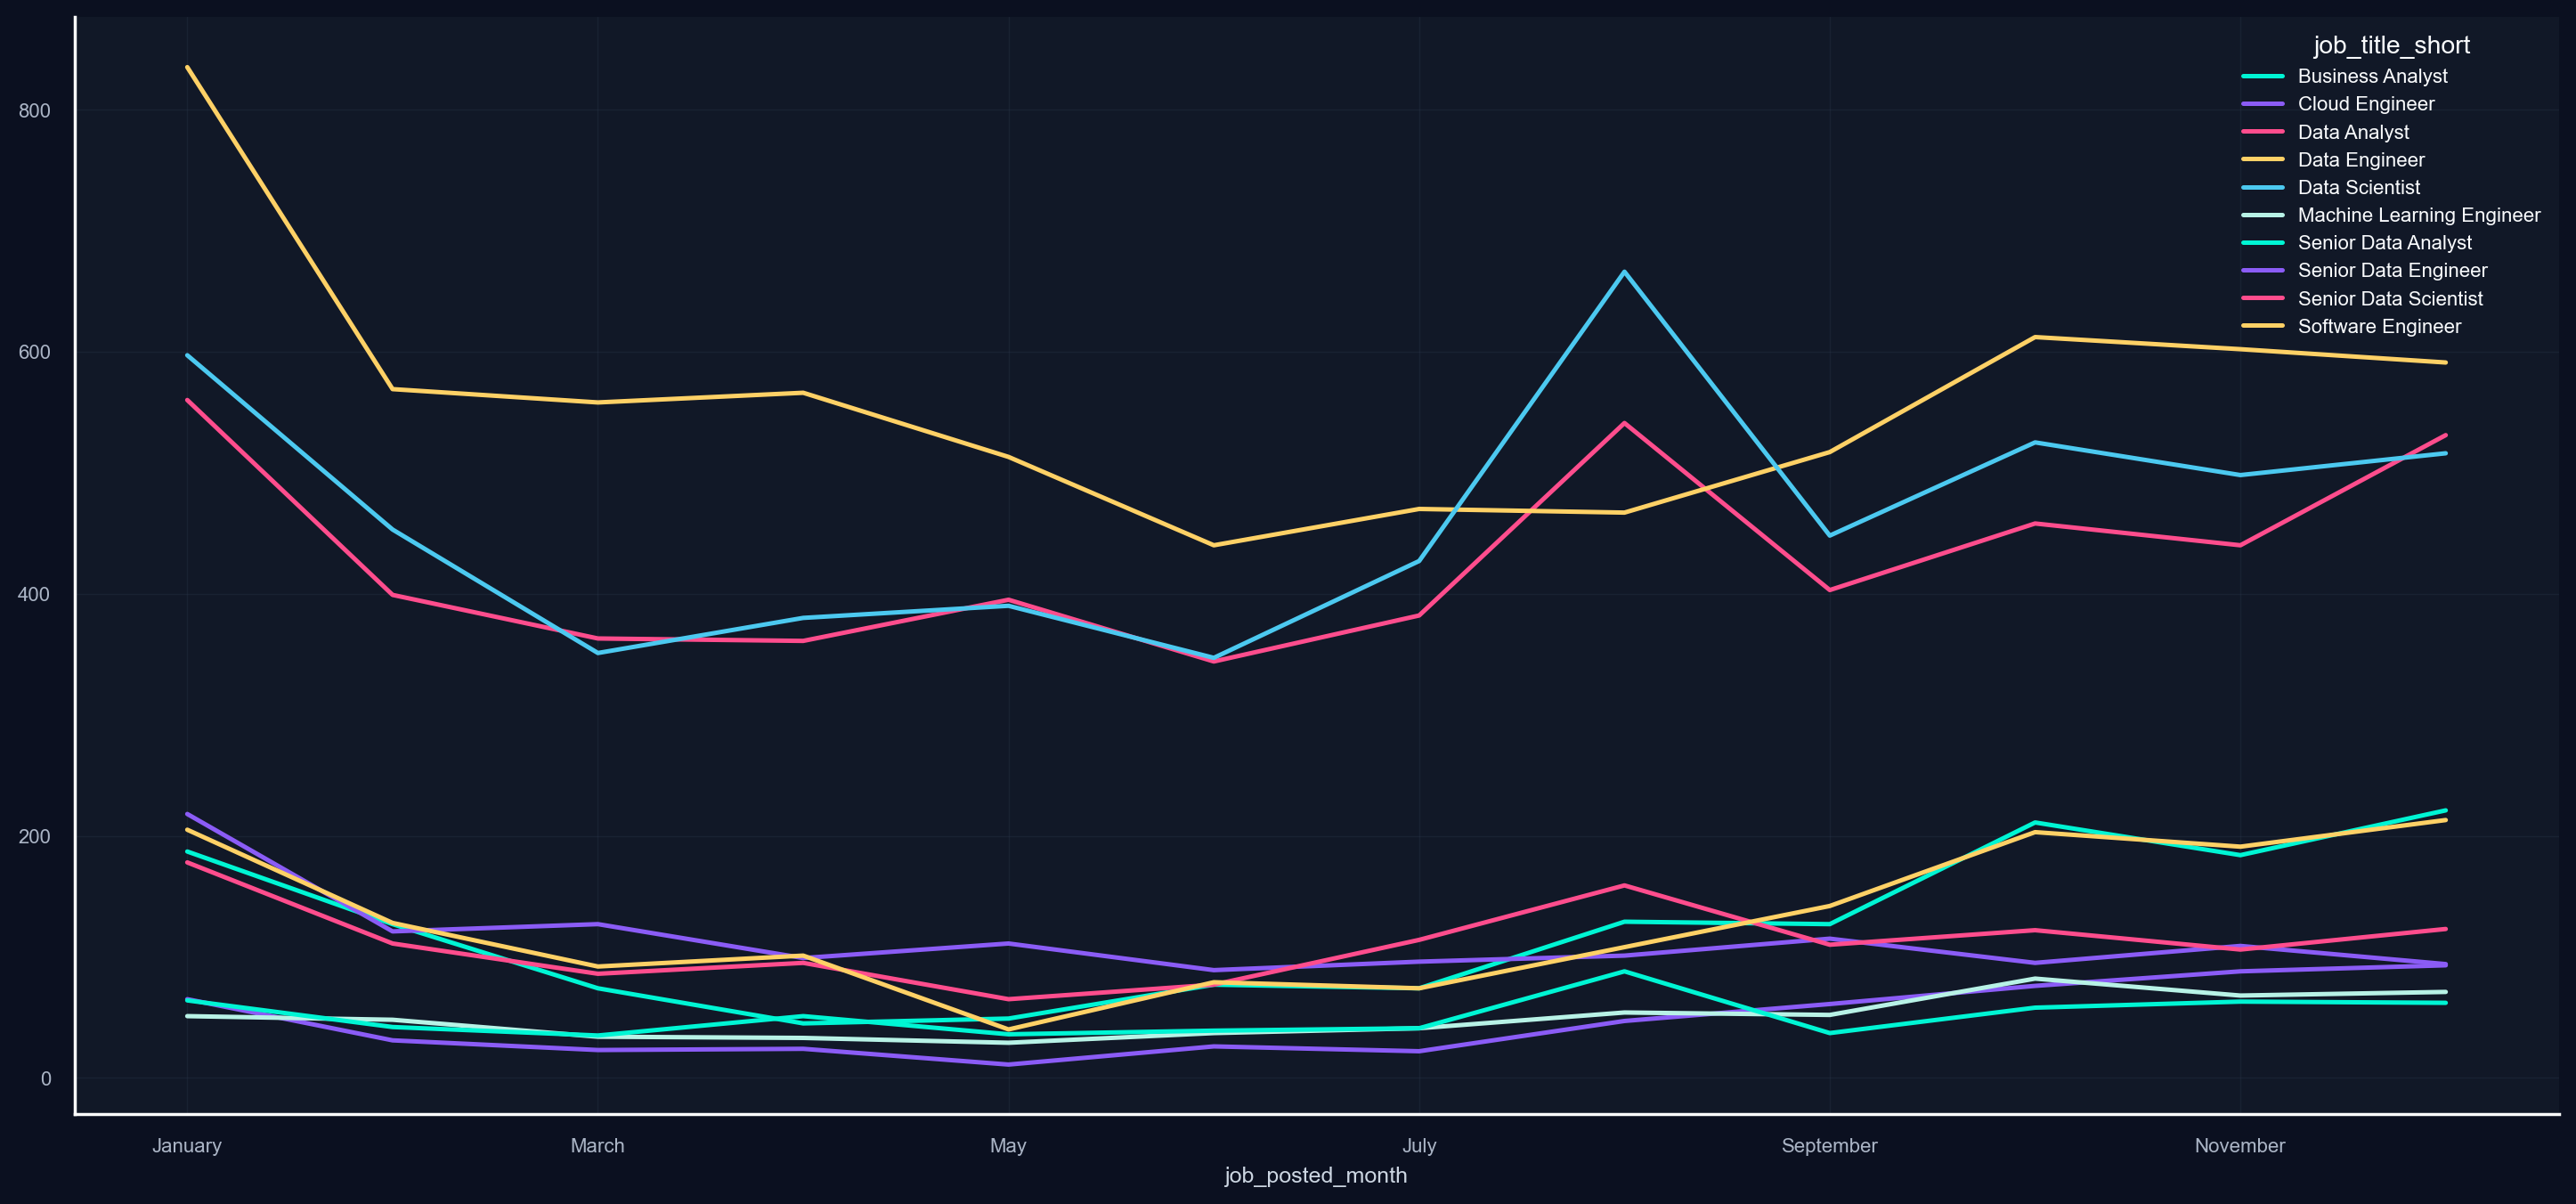

In [183]:
df_spain_pivot_cleaned.plot(kind='line', figsize=(18, 8))

## Line chart of the top 3 job posted by month in 2023 in Spain 

In [189]:
top_3_jobs = df_spain['job_title_short'].value_counts().head(3)

In [192]:
top_3_jobs = top_3_jobs.index.tolist()

<Axes: xlabel='2023', ylabel='Job Count'>

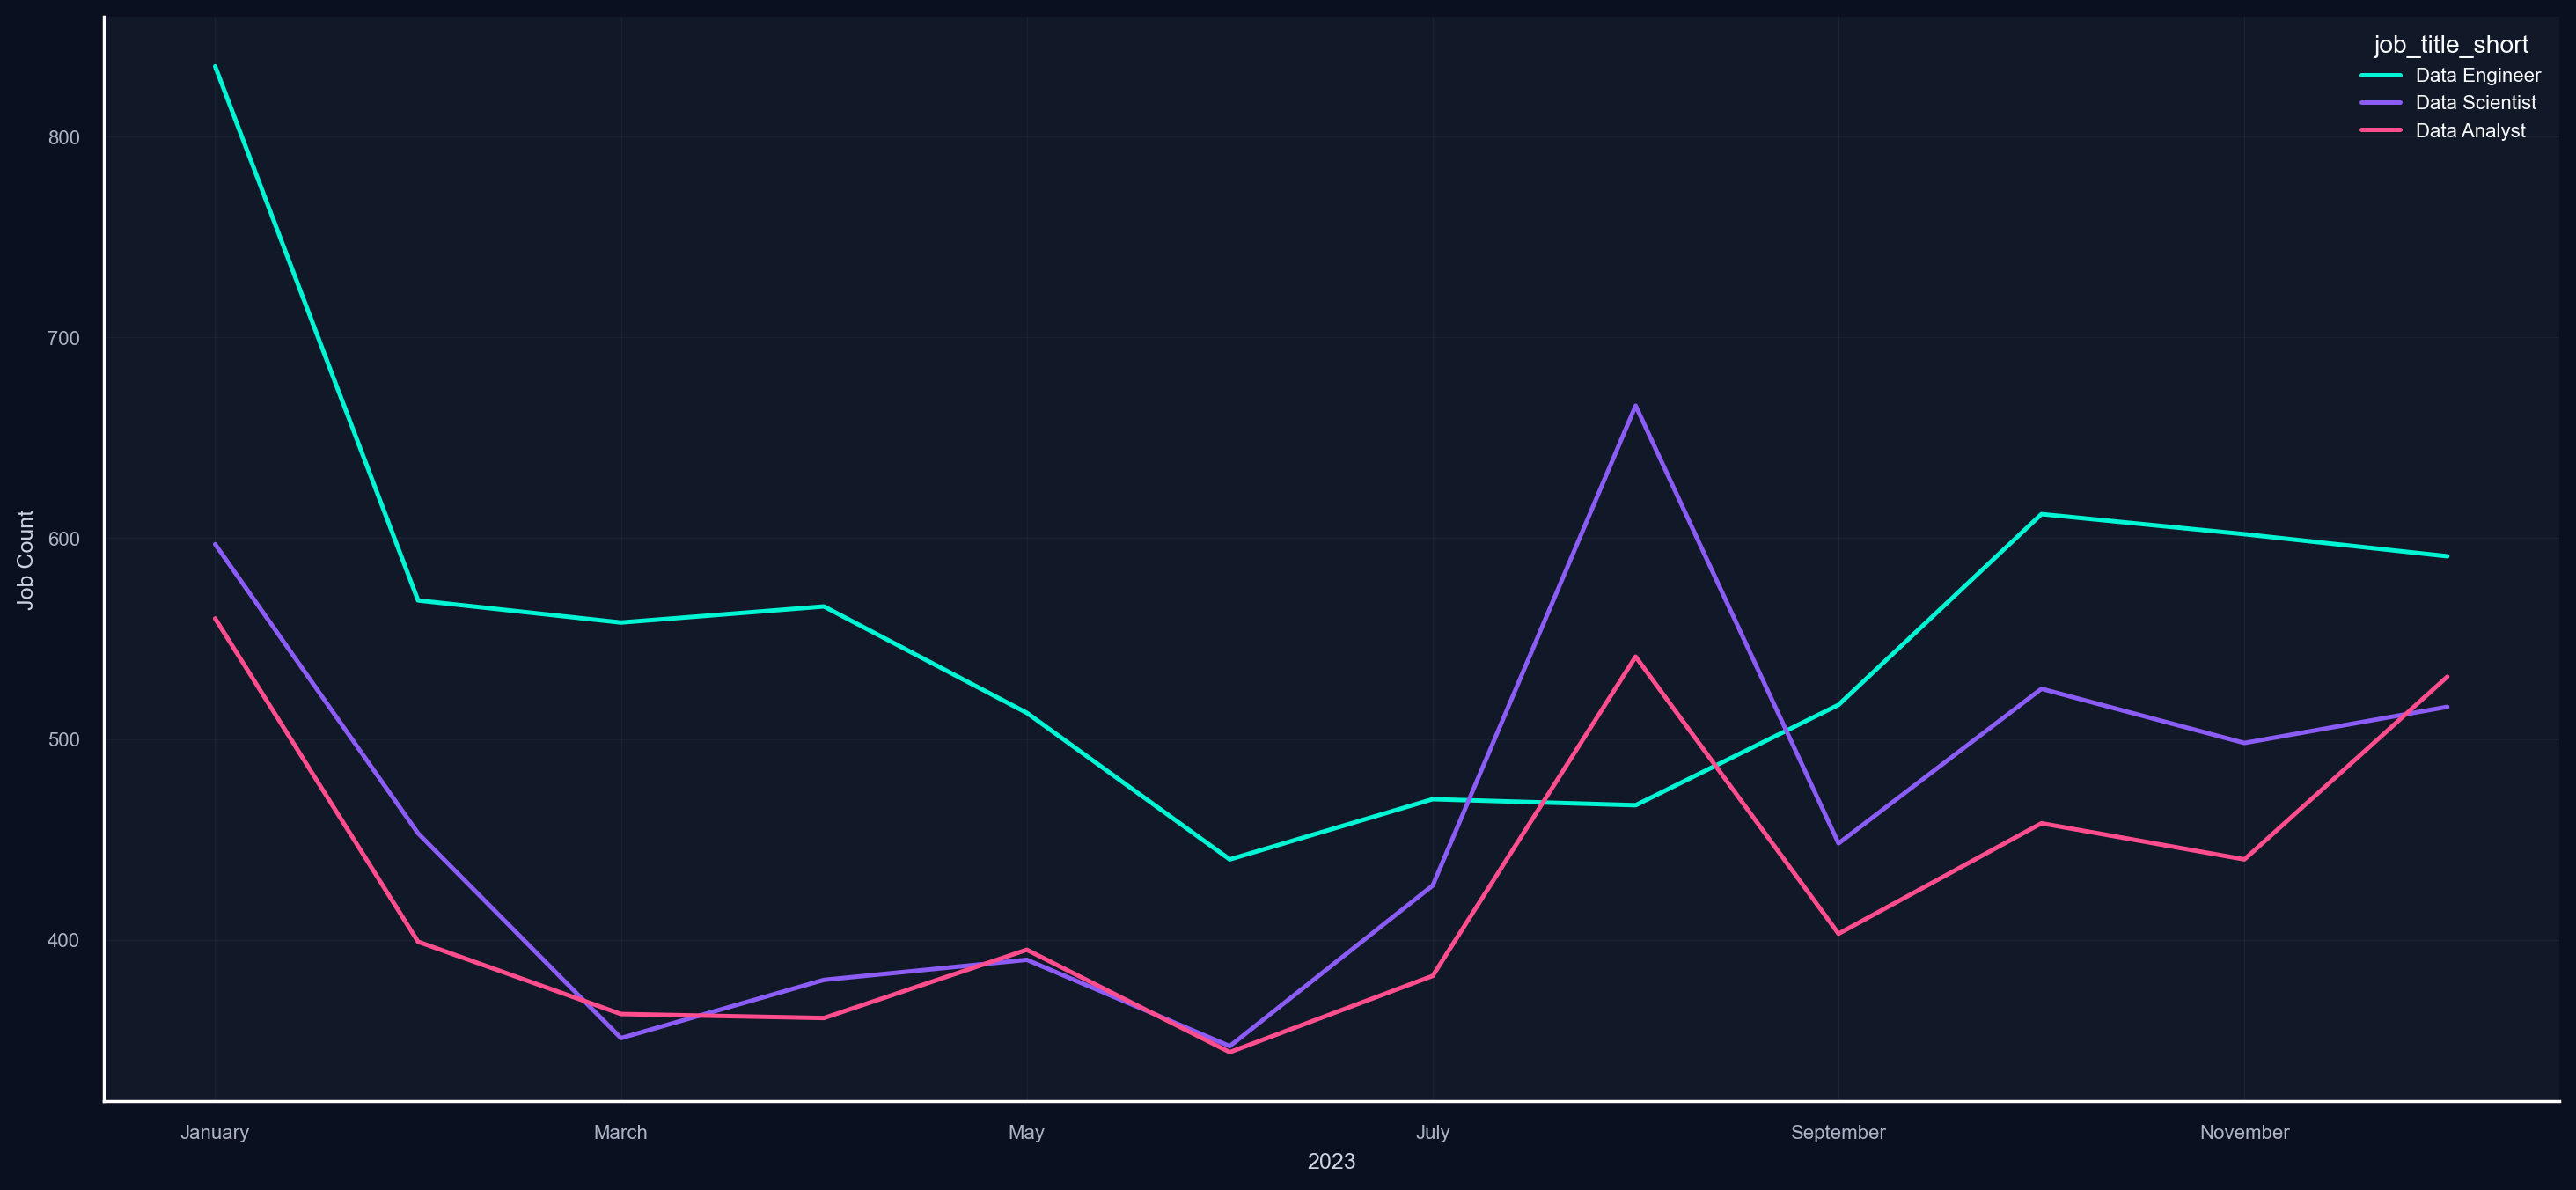

In [201]:
df_spain_pivot_cleaned[top_3_jobs].plot(kind='line', xlabel='2023', ylabel='Job Count', figsize=(18, 8))